# Дополнительное задание. Нейронная сеть на TensorFlow: кросс-валидация, подбор гиперпараметров, TensorBoard

**Датасет:** Pima Indians Diabetes (https://www.kaggle.com/datasets/kumargh/pimaindiansdiabetescsv).

**Цель:** освоить пайплайн обучения нейронной сети для классификации на TensorFlow: кросс-валидацию, подбор гиперпараметров и мониторинг обучения.

**План:**
1. Загрузить данные, выполнить первичный анализ и предобработку.
2. Построить baseline-модели и зафиксировать их accuracy на отложенной выборке.
3. Организовать 5-кратную стратифицированную кросс-валидацию.
4. Подобрать скорость обучения (3 значения) и архитектуру (3 варианта) методом Grid Search с кросс-валидацией.
5. Отследить accuracy и loss на каждом фолде в TensorBoard.
6. Сравнить конфигурации, выбрать лучшую и сравнить её с baseline на отложенной выборке.

## 1. Загрузка и подготовка данных

In [4]:
import os
import random
import shutil
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

warnings.filterwarnings("ignore")

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)

LOG_ROOT = "logs_extra"
shutil.rmtree(LOG_ROOT, ignore_errors=True)

sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 110

Подключил библиотеки, зафиксировал `SEED = 42` для Python, NumPy и TensorFlow и задал папку `logs_extra` для логов TensorBoard.

In [5]:
COLUMNS = ["Pregnancies", "Glucose", "BloodPressure", "SkinThickness",
           "Insulin", "BMI", "DiabetesPedigreeFunction", "Age", "Outcome"]

DATA_PATH = "pima-indians-diabetes.csv"
URL_FALLBACK = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
src = DATA_PATH if os.path.exists(DATA_PATH) else URL_FALLBACK
df = pd.read_csv(src, header=None, names=COLUMNS)

print("Размер таблицы:", df.shape)
display(df.head())
display(df.dtypes.to_frame("тип").T)

Размер таблицы: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
тип,int64,int64,int64,int64,int64,float64,float64,int64,int64


Загрузил таблицу: **768 строк, 8 входных признаков и целевая переменная `Outcome`** (1 — диабет, 0 — нет). Заголовка в файле нет, поэтому имена столбцов задал вручную.

**Типы признаков:** все признаки числовые (целые и вещественные), категориальных нет. Поэтому кодирование категорий (one-hot и т. п.) не требуется. Целевая переменная уже закодирована как 0/1. Из предобработки нужны только работа с пропусками и масштабирование.

         объектов   доля
Outcome                 
0             500  0.651
1             268  0.349


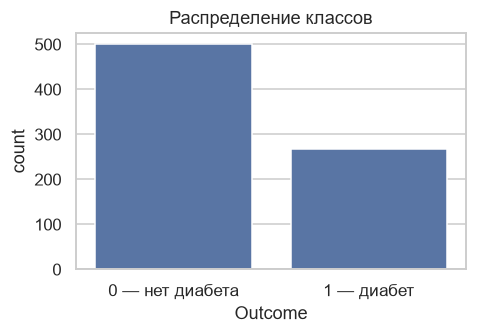

In [6]:
counts = df["Outcome"].value_counts().sort_index()
shares = (counts / len(df)).round(3)
print(pd.DataFrame({"объектов": counts, "доля": shares}).to_string())

fig, ax = plt.subplots(figsize=(4.5, 3.2))
sns.countplot(data=df, x="Outcome", ax=ax)
ax.set_xticks([0, 1])
ax.set_xticklabels(["0 — нет диабета", "1 — диабет"])
ax.set_title("Распределение классов")
plt.tight_layout()
plt.show()

Класс 0 содержит **500** объектов (65,1%), класс 1 — **268** (34,9%). Классы **умеренно несбалансированы**: модель, которая всегда отвечает «нет диабета», получит accuracy ≈ 0,651. Это нижняя планка, с которой нужно сравнивать все модели.

**Вывод о преобразованиях.** Дисбаланс не такой сильный, чтобы применять oversampling или веса классов. Достаточно **стратифицированного** разбиения (train/test и фолды кросс-валидации), чтобы доля классов сохранялась везде. Основная метрика по заданию — accuracy, но интерпретирую её относительно 0,651.

In [7]:
ZERO_AS_MISSING = ["Glucose", "BloodPressure", "SkinThickness", "Insulin", "BMI"]

print("Пропусков (NaN) в исходной таблице:", int(df.isna().sum().sum()))
zeros = (df[ZERO_AS_MISSING] == 0).sum().to_frame("число нулей")
zeros["доля, %"] = (zeros["число нулей"] / len(df) * 100).round(1)
display(zeros)

df_clean = df.copy()
df_clean[ZERO_AS_MISSING] = df_clean[ZERO_AS_MISSING].replace(0, np.nan)
print("NaN после замены нулей:", int(df_clean.isna().sum().sum()))

Пропусков (NaN) в исходной таблице: 0


,число нулей,"доля, %"
Glucose,5,0.7
BloodPressure,35,4.6
SkinThickness,227,29.6
Insulin,374,48.7
BMI,11,1.4


NaN после замены нулей: 652


Формальных пропусков (`NaN`) в данных нет, но в пяти столбцах (`Glucose`, `BloodPressure`, `SkinThickness`, `Insulin`, `BMI`) стоят нули, которые физиологически невозможны. Это скрытые пропуски: больше всего их в `Insulin` и `SkinThickness`. Заменил нули на `NaN`. Заполнять их буду медианой, но не сразу по всей таблице, а отдельно для каждого разбиения (только по обучающей части), чтобы не было утечки информации из валидации и теста.

In [8]:
X = df_clean.drop(columns="Outcome")
y = df_clean["Outcome"]
N_FEATURES = X.shape[1]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED)

def fit_prep(X_fit):
    """Заполнение пропусков медианой + стандартизация; параметры считаются только по X_fit."""
    return Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())]).fit(X_fit)

def to_arrays(prep, *frames):
    return [prep.transform(f).astype("float32") for f in frames]

prep_full = fit_prep(X_train)
Xtr, Xte = to_arrays(prep_full, X_train, X_test)
ytr, yte = y_train.values.astype("float32"), y_test.values.astype("float32")

print("train:", Xtr.shape, "| доля класса 1:", round(ytr.mean(), 3))
print("test: ", Xte.shape, "| доля класса 1:", round(yte.mean(), 3))

train: (614, 8) | доля класса 1: 0.349
test:  (154, 8) | доля класса 1: 0.351


Разделил данные на обучающую (614 объектов) и отложенную тестовую (154 объекта) выборки в пропорции 80/20 со стратификацией; доля класса 1 почти одинакова (34,9% и 35,1%). **Тест используется только для сравнения baseline и финальной модели.** Кросс-валидация и подбор гиперпараметров идут только внутри обучающей части.

Функция `fit_prep` собирает предобработку (медиана + стандартизация). Её параметры считаются только по той выборке, на которой она обучена. Это важно для кросс-валидации: на каждом фолде предобработка заново обучается на обучающих фолдах и применяется к валидационному.

## 2. Baseline-модели

Зафиксирую точку отсчёта тремя моделями:
- **Dummy** — всегда предсказывает самый частый класс (нижняя планка);
- **логистическая регрессия** — простая линейная модель;
- **baseline-нейросеть** с фиксированной архитектурой 8 → 16 → 8 → 1 (ReLU, Adam, `lr = 1e-3`, 100 эпох, batch 32).

In [9]:
dummy = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr)
logreg = LogisticRegression(max_iter=1000).fit(Xtr, ytr)

acc_dummy = dummy.score(Xte, yte)
acc_logreg = logreg.score(Xte, yte)
print(f"Dummy (самый частый класс): accuracy на тесте = {acc_dummy:.3f}")
print(f"Логистическая регрессия:    accuracy на тесте = {acc_logreg:.3f}")

Dummy (самый частый класс): accuracy на тесте = 0.649
Логистическая регрессия:    accuracy на тесте = 0.708


Dummy-модель даёт точность, равную доле класса 0 в тесте. Логистическая регрессия показывает, насколько линейная модель превосходит эту планку. На тесте dummy-модель получила 0,649, а логистическая регрессия — 0,708, то есть линейная модель лучше самой простой планки примерно на 6 п.п.

In [10]:
EPOCHS = 100
BATCH = 32

def build_model(hidden, lr, dropout=0.0):
    """Полносвязная сеть: Dense (+Dropout) ... -> Dense(1, sigmoid)."""
    model = keras.Sequential()
    model.add(keras.Input(shape=(N_FEATURES,)))
    for units in hidden:
        model.add(layers.Dense(units, activation="relu"))
        if dropout > 0:
            model.add(layers.Dropout(dropout))
    model.add(layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(learning_rate=lr),
                  loss="binary_crossentropy", metrics=["accuracy"])
    return model

def train_model(cfg, X_fit, y_fit, X_val=None, y_val=None, seed=SEED, tb_dir=None):
    """Обучает сеть EPOCHS эпох; при tb_dir пишет логи TensorBoard. Возвращает модель, историю и время."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(seed)
    model = build_model(cfg["hidden"], cfg["lr"], cfg.get("dropout", 0.0))
    callbacks = [keras.callbacks.TensorBoard(log_dir=tb_dir)] if tb_dir else []
    val = (X_val, y_val) if X_val is not None else None
    t0 = time.time()
    hist = model.fit(X_fit, y_fit, validation_data=val, epochs=EPOCHS,
                     batch_size=BATCH, callbacks=callbacks, verbose=0)
    return model, pd.DataFrame(hist.history), time.time() - t0

def test_runs(cfg, name, seeds=range(5)):
    """Обучает модель на всей train-выборке с разными seed и оценивает на тесте (нейросеть чувствительна к seed)."""
    rows = []
    for s in seeds:
        model, _, t = train_model(cfg, Xtr, ytr, seed=s, tb_dir=f"{LOG_ROOT}/final/{name}/seed_{s}")
        loss, acc = model.evaluate(Xte, yte, verbose=0)
        rows.append({"seed": s, "test_accuracy": acc, "test_loss": loss, "time_s": t})
    return pd.DataFrame(rows)

Написал две функции. `build_model` собирает сеть с заданными слоями, скоростью обучения и dropout, а `train_model` обучает её фиксированное число эпох (100) и при необходимости пишет логи в TensorBoard. Ранняя остановка не используется: нужно честно сравнить конфигурации при одинаковом протоколе, а валидационные данные не должны влиять на обучение. Функция `test_runs` обучает модель на всей обучающей выборке с пятью разными seed и оценивает на тесте: у небольшой сети результат заметно зависит от случайной инициализации, поэтому одного запуска недостаточно.

In [11]:
BASE_CFG = {"hidden": (16, 8), "lr": 1e-3, "dropout": 0.0}
base_test = test_runs(BASE_CFG, "baseline_16-8_lr0.001")
display(base_test.round(4))
print(f"Baseline-нейросеть: test accuracy = {base_test.test_accuracy.mean():.3f} ± {base_test.test_accuracy.std():.3f} (5 seeds)")

,seed,test_accuracy,test_loss,time_s
0,0,0.7078,0.5356,24.3567
1,1,0.7662,0.5218,15.5644
2,2,0.7403,0.5920,16.3742
3,3,0.7403,0.5580,15.5333
4,4,0.7468,0.5569,15.2153


Baseline-нейросеть: test accuracy = 0.740 ± 0.021 (5 seeds)


Обучил baseline-нейросеть пять раз с разными seed. В таблице точность и loss на тесте каждого запуска, а в строке под ней среднее и стандартное отклонение по seed. Это точка отсчёта для сравнения с настроенной моделью. Средняя точность baseline-нейросети составила 0,740 ± 0,021, то есть примерно на 3 п.п. выше логистической регрессии; по seed результат колеблется от 0,708 до 0,766.

## 3. Кросс-валидация

Использую 5-кратную **стратифицированную** кросс-валидацию (`StratifiedKFold`, перемешивание с фиксированным seed) на обучающей выборке. Каждый объект ровно один раз попадает в валидацию, а доля классов в каждом фолде сохраняется.

In [12]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
folds = list(skf.split(X_train, y_train))

fold_info = pd.DataFrame([{"фолд": k, "train": len(tr), "val": len(va),
                           "доля класса 1 в train": y_train.iloc[tr].mean(),
                           "доля класса 1 в val": y_train.iloc[va].mean()}
                          for k, (tr, va) in enumerate(folds, 1)]).set_index("фолд")
display(fold_info.round(3))

,train,val,доля класса 1 в train,доля класса 1 в val
фолд,,,,
1,491,123,0.348,0.350
2,491,123,0.348,0.350
3,491,123,0.348,0.350
4,491,123,0.348,0.350
5,492,122,0.350,0.344


Разбил обучающую выборку на 5 фолдов. В таблице размеры частей и доля класса 1: она почти одинакова во всех фолдах (около 0,35), то есть стратификация сработала и фолды сопоставимы между собой. Фолды вычисляются один раз, поэтому все конфигурации оцениваются на одних и тех же разбиениях.

## 4. Подбор гиперпараметров (Grid Search)

Сетка из **3 скоростей обучения × 3 архитектур = 9 конфигураций**; каждая оценивается по 5 фолдам, то есть всего 45 обучений.

| Гиперпараметр | Значения |
|---|---|
| Скорость обучения Adam | `1e-4`, `1e-3`, `1e-2` |
| Архитектура A | один скрытый слой на 8 нейронов |
| Архитектура B | два слоя 16 → 8 |
| Архитектура C | три слоя 64 → 32 → 16 с Dropout 0,3 после каждого слоя |

Значения скорости обучения охватывают малую (вероятно, недообучение), среднюю и большую (вероятно, быстрое переобучение). Архитектуры различаются по ёмкости; в C добавлен dropout, чтобы проверить регуляризацию. Конфигурация B при `lr = 1e-3` совпадает с baseline-нейросетью, поэтому baseline входит в сетку.

**Протокол.** На каждом фолде: предобработка обучается только на обучающих фолдах, сеть учится 100 эпох, затем фиксируются метрики **в последней эпохе** (без выбора лучшей эпохи по валидации, чтобы оценка не была завышена). Дополнительно сохраняются минимум `val_loss` и эпоха, на которой он достигнут, для диагностики переобучения. Для каждого фолда пишутся логи TensorBoard в `logs_extra/cv/<конфигурация>/fold_<k>`.

In [13]:
LRS = [1e-4, 1e-3, 1e-2]
ARCHS = {
    "A_8":              {"hidden": (8,),         "dropout": 0.0},
    "B_16-8":           {"hidden": (16, 8),      "dropout": 0.0},
    "C_64-32-16_do0.3": {"hidden": (64, 32, 16), "dropout": 0.3},
}
print("Конфигураций:", len(LRS) * len(ARCHS), "| обучений:", len(LRS) * len(ARCHS) * len(folds))

Конфигураций: 9 | обучений: 45


Задал сетку гиперпараметров: 3 значения `lr` и 3 архитектуры дают 9 конфигураций, а вместе с 5 фолдами 45 обучений.

In [ ]:
records, histories = [], {}

for arch_name, arch in ARCHS.items():
    for lr in LRS:
        cfg_name = f"{arch_name}__lr{lr:g}"
        cfg = {**arch, "lr": lr}
        for k, (tr_idx, va_idx) in enumerate(folds, 1):
            X_tr_raw, X_va_raw = X_train.iloc[tr_idx], X_train.iloc[va_idx]
            y_tr = y_train.iloc[tr_idx].values.astype("float32")
            y_va = y_train.iloc[va_idx].values.astype("float32")
            prep = fit_prep(X_tr_raw)
            Xa, Xv = to_arrays(prep, X_tr_raw, X_va_raw)

            _, h, t = train_model(cfg, Xa, y_tr, Xv, y_va, tb_dir=f"{LOG_ROOT}/cv/{cfg_name}/fold_{k}")
            histories[(cfg_name, k)] = h
            b = h["val_loss"].idxmin()
            records.append({"config": cfg_name, "arch": arch_name, "lr": lr, "fold": k,
                            "val_accuracy": h["val_accuracy"].iloc[-1], "val_loss": h["val_loss"].iloc[-1],
                            "train_accuracy": h["accuracy"].iloc[-1], "train_loss": h["loss"].iloc[-1],
                            "best_val_loss": h.loc[b, "val_loss"], "best_epoch": b + 1, "time_s": t})
        acc = [r["val_accuracy"] for r in records if r["config"] == cfg_name]
        print(f"{cfg_name:28s} val accuracy = {np.mean(acc):.3f} ± {np.std(acc, ddof=1):.3f}")

cv_df = pd.DataFrame(records)

A_8__lr0.0001                val accuracy = 0.634 ± 0.027
A_8__lr0.001                 val accuracy = 0.785 ± 0.017
A_8__lr0.01                  val accuracy = 0.761 ± 0.022
B_16-8__lr0.0001             val accuracy = 0.653 ± 0.016
B_16-8__lr0.001              val accuracy = 0.779 ± 0.013
B_16-8__lr0.01               val accuracy = 0.718 ± 0.025
C_64-32-16_do0.3__lr0.0001   val accuracy = 0.788 ± 0.028
C_64-32-16_do0.3__lr0.001    val accuracy = 0.772 ± 0.013
C_64-32-16_do0.3__lr0.01     val accuracy = 0.746 ± 0.019


Запустил Grid Search: для каждой из 9 конфигураций и каждого из 5 фолдов обучил сеть и сохранил метрики в таблицу `cv_df` (точность и loss на обучающем и валидационном фолде, минимум `val_loss`, эпоха минимума, время обучения). Полные кривые обучения всех 45 запусков сохранены в `histories`. Под ячейкой для каждой конфигурации напечатаны средняя валидационная accuracy и её стандартное отклонение по фолдам. Лучшие средние значения у C при `lr = 1e-4` (0,788), A при `lr = 1e-3` (0,785) и B при `lr = 1e-3` (0,779). При `lr = 1e-4` архитектуры A и B показывают самые низкие результаты (0,634 и 0,653), а при `lr = 1e-2` все три архитектуры хуже, чем при `lr = 1e-3`. Разброс между фолдами составляет от 0,013 до 0,028.

In [15]:
from tensorboard.plugins.hparams import api as hp

for (arch_name, lr), g in cv_df.groupby(["arch", "lr"]):
    with tf.summary.create_file_writer(f"{LOG_ROOT}/hparams/{arch_name}__lr{lr:g}").as_default():
        hp.hparams({"arch": arch_name, "lr": float(lr)})
        tf.summary.scalar("cv_accuracy", float(g["val_accuracy"].mean()), step=1)

Дополнительно записал в TensorBoard сводку по гиперпараметрам: средняя CV-accuracy каждой конфигурации появится на вкладке HParams.

## 5. Мониторинг обучения в TensorBoard

Логи accuracy и loss записаны для **каждого фолда каждой конфигурации** (серии `train` и `validation`).

In [16]:
%load_ext tensorboard
%tensorboard --logdir logs_extra

Reusing TensorBoard on port 6007 (pid 7256), started 0:55:08 ago. (Use '!kill 7256' to kill it.)

Запустил TensorBoard на папке `logs_extra` (адрес http://localhost:6006).

**Что смотреть:**
- вкладка **Scalars**: графики `epoch_accuracy` и `epoch_loss`. Каждый запуск называется `cv/<конфигурация>/fold_<k>`, внутри него серии `train` и `validation`. В поле фильтра можно ввести, например, `B_16-8__lr0.001`, чтобы увидеть пять фолдов одной конфигурации, или `fold_1`, чтобы сравнить разные конфигурации на одном фолде;
- вкладка **HParams**: таблица и график всех 9 конфигураций с их средней CV-accuracy;
- запуски `final/...` содержат обучение baseline и лучшей модели на полной обучающей выборке (только кривые train).

## 6. Сравнение конфигураций

In [17]:
summary = (cv_df.groupby(["arch", "lr"])
           .agg(acc_mean=("val_accuracy", "mean"), acc_std=("val_accuracy", "std"),
                loss_mean=("val_loss", "mean"), loss_std=("val_loss", "std"),
                train_acc=("train_accuracy", "mean"), best_val_loss=("best_val_loss", "mean"),
                best_epoch=("best_epoch", "mean"), time_s=("time_s", "mean"))
           .reset_index())
summary["gap_acc"] = summary["train_acc"] - summary["acc_mean"]          # разрыв train - validation по accuracy
summary["loss_rise"] = summary["loss_mean"] - summary["best_val_loss"]   # рост val_loss к концу обучения
summary = summary.sort_values("acc_mean", ascending=False).reset_index(drop=True)

display(summary.round(4))

,arch,lr,acc_mean,acc_std,loss_mean,loss_std,train_acc,best_val_loss,best_epoch,time_s,gap_acc,loss_rise
0,C_64-32-16_do0.3,0.0001,0.7882,0.0280,0.4611,0.0205,0.7585,0.4611,99.6,40.2065,-0.0297,0.0000
1,A_8,0.0010,0.7850,0.0168,0.4559,0.0286,0.7940,0.4540,81.2,28.8332,0.0090,0.0020
2,B_16-8,0.0010,0.7785,0.0131,0.4665,0.0404,0.8257,0.4509,42.2,29.5898,0.0472,0.0156
3,C_64-32-16_do0.3,0.0010,0.7720,0.0126,0.4887,0.0534,0.8164,0.4478,31.8,30.1766,0.0444,0.0409
4,A_8,0.0100,0.7605,0.0217,0.5225,0.0824,0.8257,0.4505,16.0,29.0719,0.0652,0.0720
5,C_64-32-16_do0.3,0.0100,0.7459,0.0185,0.8192,0.2411,0.8721,0.4481,8.2,30.0833,0.1262,0.3711
6,B_16-8,0.0100,0.7182,0.0251,1.6299,0.4422,0.9503,0.4453,6.8,29.4196,0.2321,1.1845
7,B_16-8,0.0001,0.6531,0.0160,0.5322,0.0165,0.6706,0.5322,100.0,29.4736,0.0175,0.0000
8,A_8,0.0001,0.6335,0.0272,0.6221,0.0139,0.6462,0.6221,100.0,29.7167,0.0126,0.0000


Свёл результаты кросс-валидации по конфигурациям и отсортировал по средней валидационной accuracy. Столбцы таблицы:
- `acc_mean`, `acc_std` — средняя accuracy на валидационных фолдах и её разброс между фолдами (**устойчивость**);
- `loss_mean`, `loss_std` — то же для loss;
- `train_acc` — средняя accuracy на обучающих фолдах;
- `best_val_loss`, `best_epoch` — минимальный `val_loss` и эпоха, на которой он достигнут;
- `time_s` — среднее время обучения одного фолда в секундах;
- `gap_acc` — разрыв train и validation по accuracy (признак **переобучения**, если он большой);
- `loss_rise` — на сколько `val_loss` в конце обучения выше своего минимума (ещё один признак переобучения).

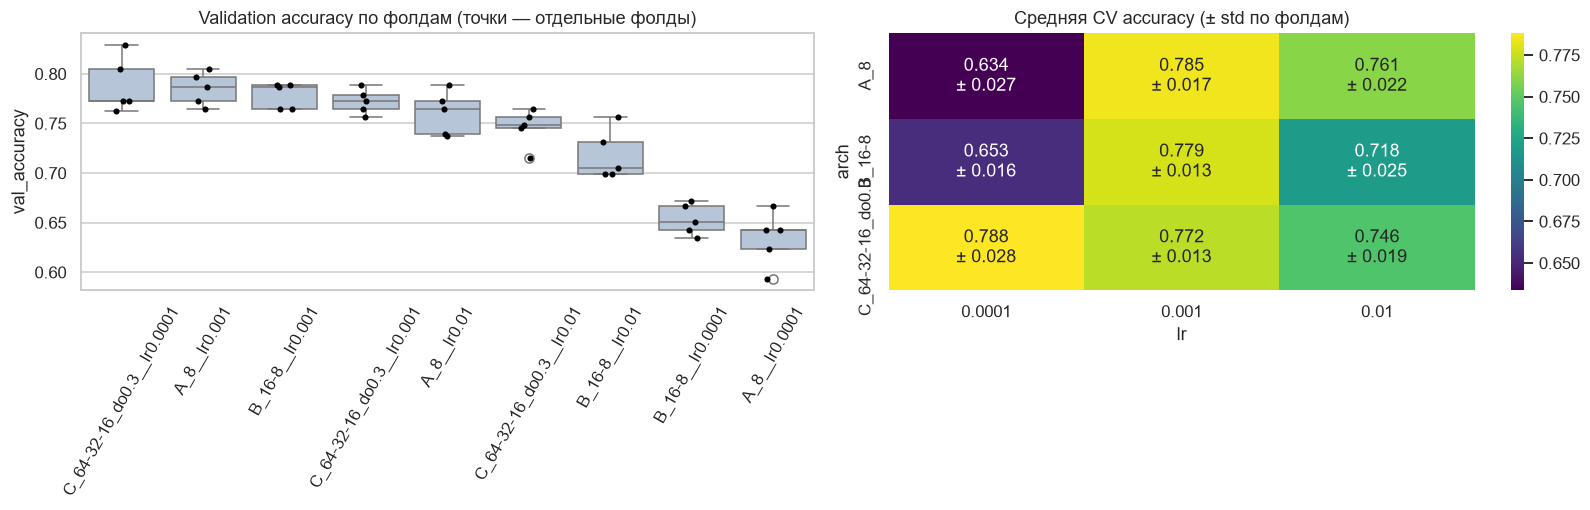

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8))

order = [f"{r.arch}__lr{r.lr:g}" for r in summary.itertuples()]
sns.boxplot(data=cv_df, x="config", y="val_accuracy", order=order, ax=axes[0], color="lightsteelblue")
sns.stripplot(data=cv_df, x="config", y="val_accuracy", order=order, ax=axes[0], color="black", size=4)
axes[0].set_title("Validation accuracy по фолдам (точки — отдельные фолды)")
axes[0].set_xlabel("")
axes[0].tick_params(axis="x", rotation=60)

piv_m = summary.pivot(index="arch", columns="lr", values="acc_mean")
piv_s = summary.pivot(index="arch", columns="lr", values="acc_std")
labels = np.array([[f"{m:.3f}\n± {sd:.3f}" for m, sd in zip(rm, rs)] for rm, rs in zip(piv_m.values, piv_s.values)])
sns.heatmap(piv_m, annot=labels, fmt="", cmap="viridis", ax=axes[1])
axes[1].set_title("Средняя CV accuracy (± std по фолдам)")
plt.tight_layout()
plt.show()

Слева ящики с усами показывают распределение валидационной accuracy по пяти фолдам для каждой конфигурации (чем ниже ящик и короче «ус», тем хуже и нестабильнее конфигурация), справа тепловая карта средней accuracy в зависимости от архитектуры и скорости обучения. Смотрю на два свойства: насколько высока средняя точность и насколько велик разброс между фолдами. Различия меньше одного стандартного отклонения при пяти фолдах считаю незначимыми.

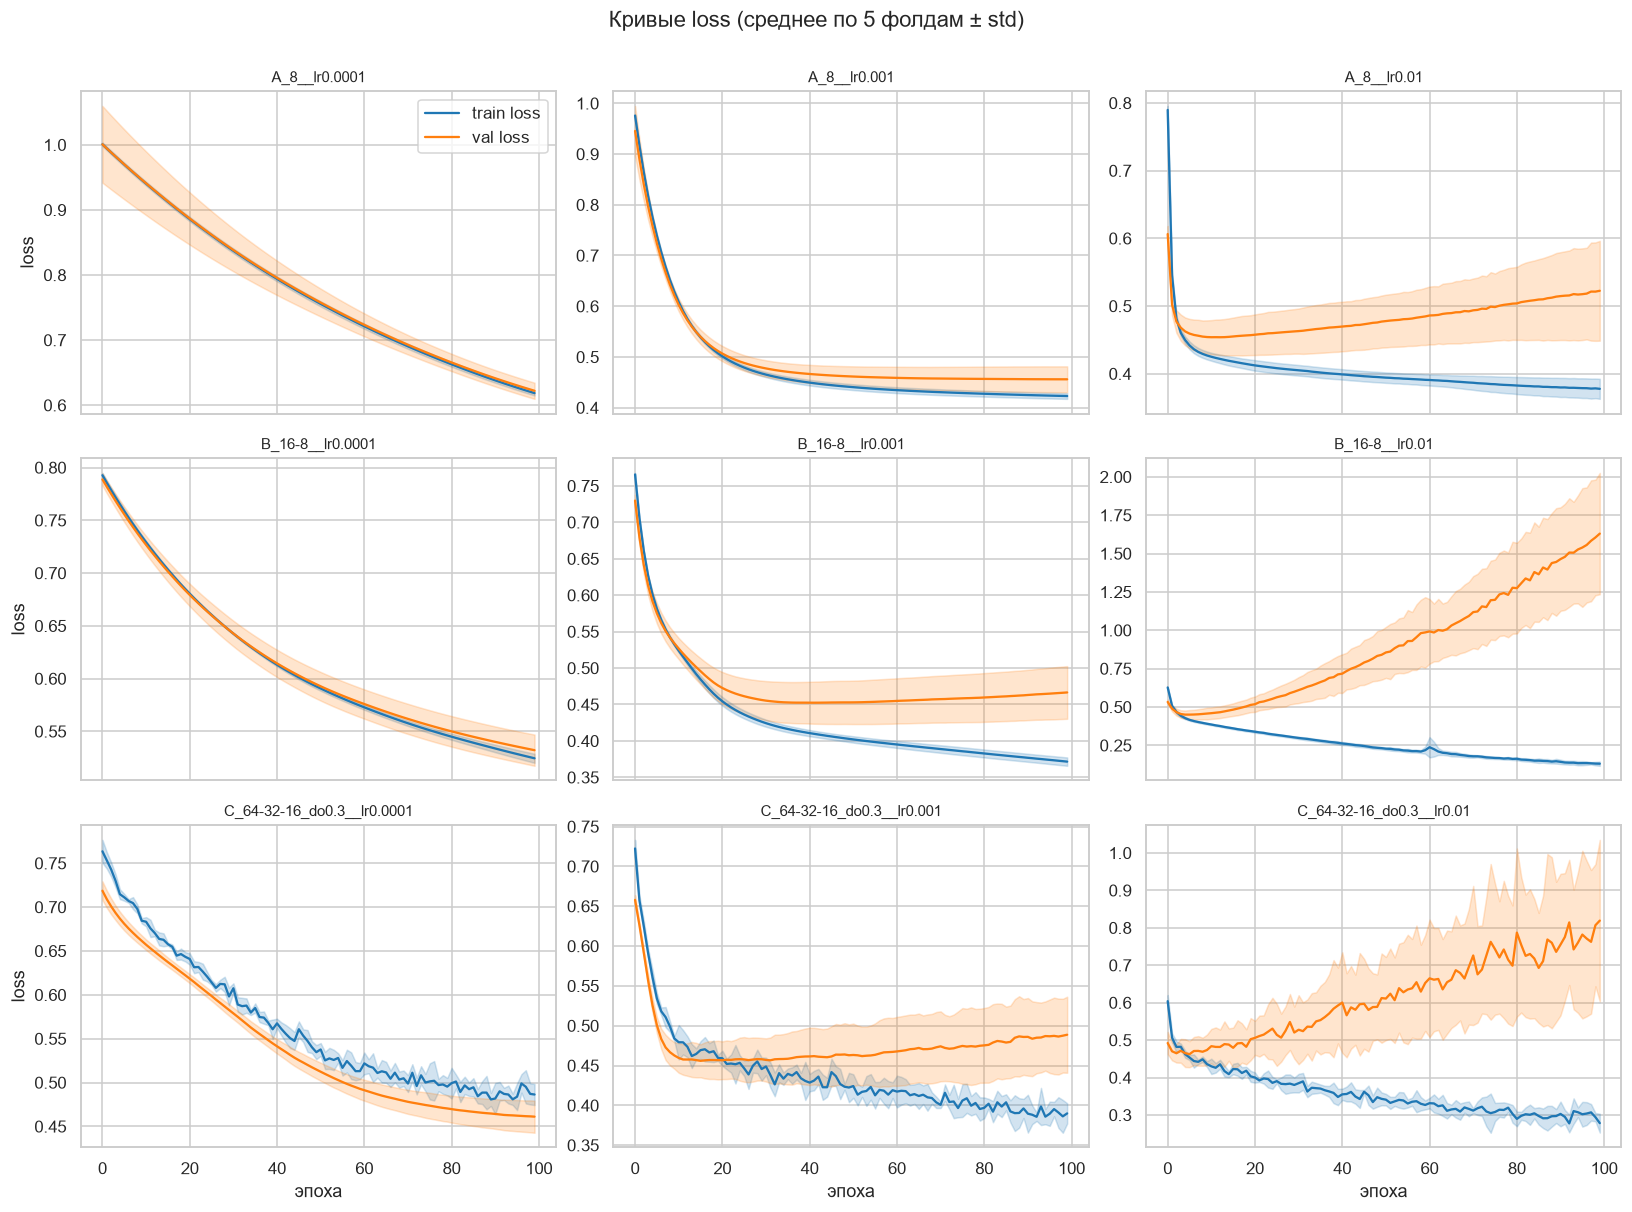

In [19]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex=True)
for i, arch_name in enumerate(ARCHS):
    for j, lr in enumerate(LRS):
        cfg_name = f"{arch_name}__lr{lr:g}"
        hs = [histories[(cfg_name, k)] for k in range(1, len(folds) + 1)]
        ax = axes[i, j]
        for col, label, color in [("loss", "train loss", "tab:blue"), ("val_loss", "val loss", "tab:orange")]:
            arr = np.array([h[col].values for h in hs])
            ax.plot(arr.mean(0), label=label, color=color)
            ax.fill_between(range(arr.shape[1]), arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), color=color, alpha=0.2)
        ax.set_title(cfg_name, fontsize=10)
        if i == 2: ax.set_xlabel("эпоха")
        if j == 0: ax.set_ylabel("loss")
        if i == 0 and j == 0: ax.legend()
plt.suptitle("Кривые loss (среднее по 5 фолдам ± std)", y=1.0)
plt.tight_layout()
plt.show()

Построил кривые loss для всех девяти конфигураций (строки — архитектуры, столбцы — скорости обучения). Линия — среднее по пяти фолдам, полоса — разброс между фолдами. Как читать: если `val loss` идёт вниз вместе с `train loss`, сеть обучается; если `val loss` поднимается, а `train loss` продолжает падать, это **переобучение**; если обе кривые к концу всё ещё высоки и медленно снижаются, это **недообучение** (обучение не завершено). Скорость обучения определяет наклон кривых, а архитектура — насколько быстро растёт разрыв между train и validation.

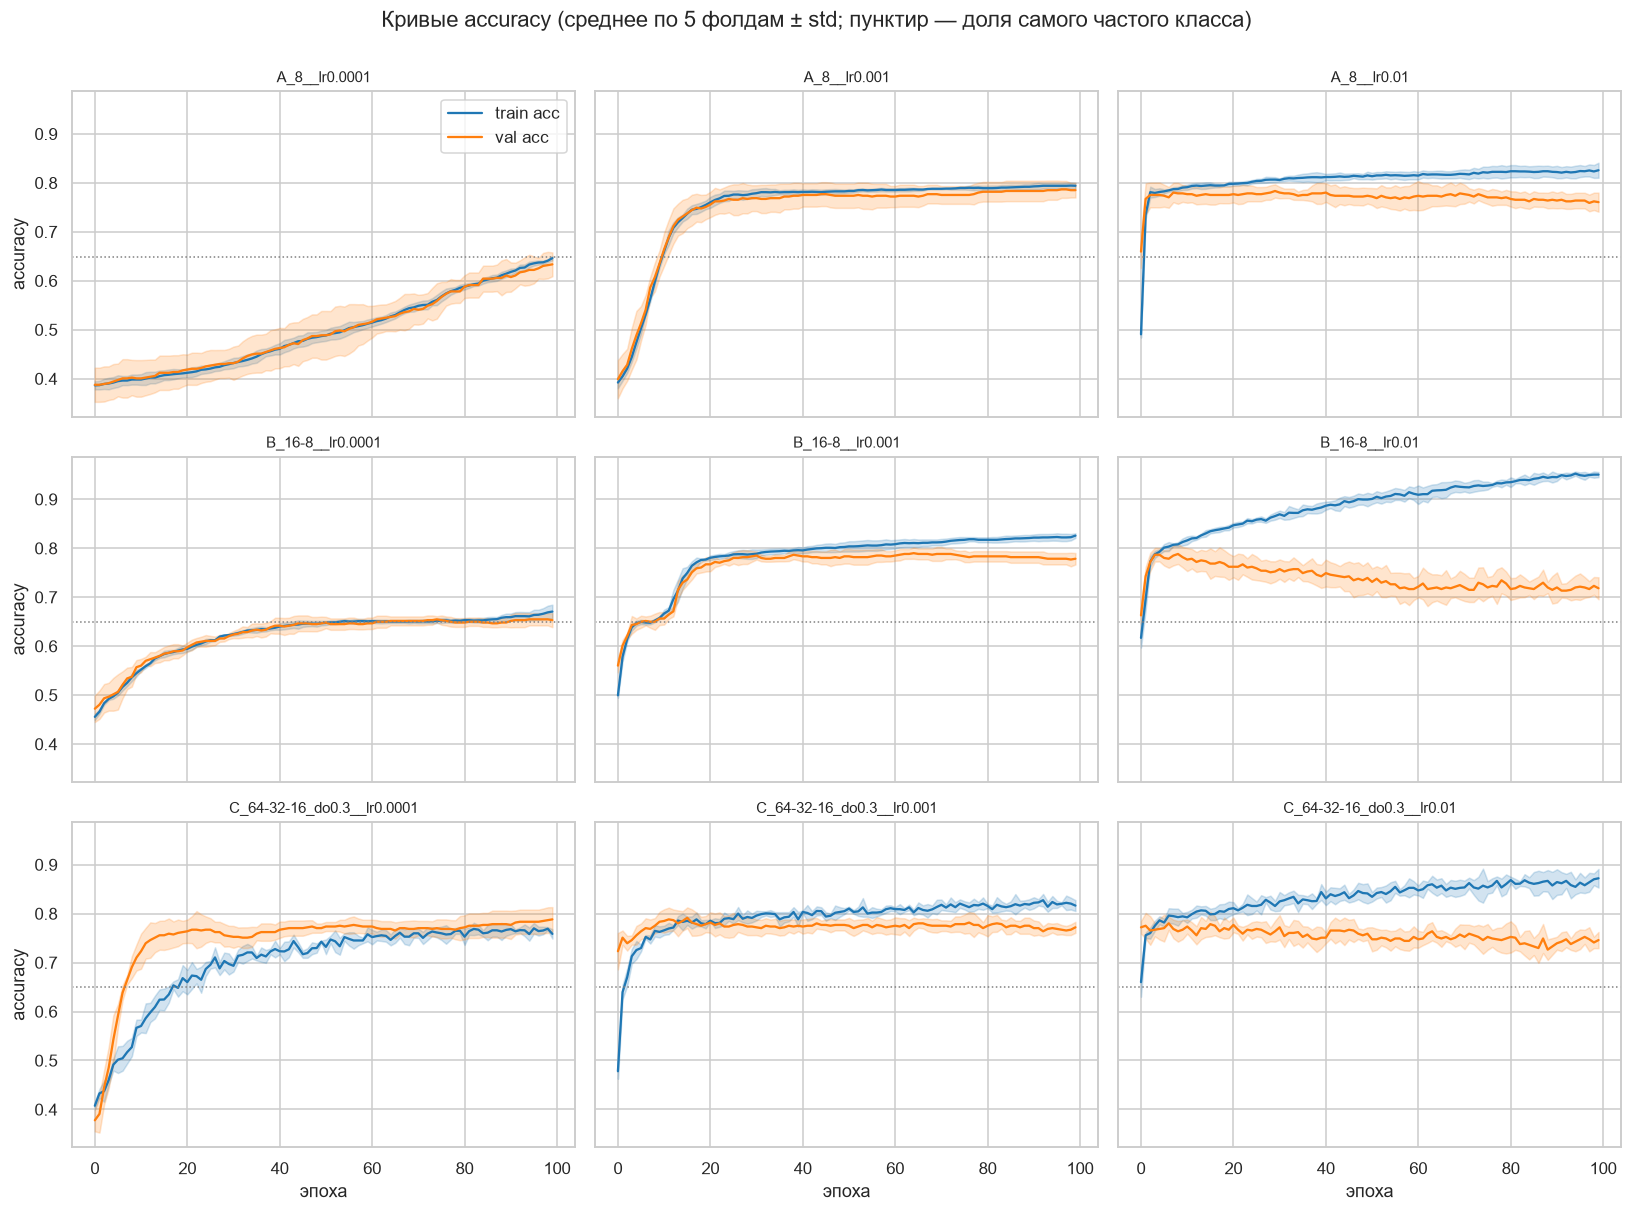

In [20]:
fig, axes = plt.subplots(3, 3, figsize=(15, 11), sharex=True, sharey=True)
for i, arch_name in enumerate(ARCHS):
    for j, lr in enumerate(LRS):
        cfg_name = f"{arch_name}__lr{lr:g}"
        hs = [histories[(cfg_name, k)] for k in range(1, len(folds) + 1)]
        ax = axes[i, j]
        for col, label, color in [("accuracy", "train acc", "tab:blue"), ("val_accuracy", "val acc", "tab:orange")]:
            arr = np.array([h[col].values for h in hs])
            ax.plot(arr.mean(0), label=label, color=color)
            ax.fill_between(range(arr.shape[1]), arr.mean(0) - arr.std(0), arr.mean(0) + arr.std(0), color=color, alpha=0.2)
        ax.axhline(acc_dummy, color="gray", ls=":", lw=1)
        ax.set_title(cfg_name, fontsize=10)
        if i == 2: ax.set_xlabel("эпоха")
        if j == 0: ax.set_ylabel("accuracy")
        if i == 0 and j == 0: ax.legend()
plt.suptitle("Кривые accuracy (среднее по 5 фолдам ± std; пунктир — доля самого частого класса)", y=1.0)
plt.tight_layout()
plt.show()

То же для accuracy. Серый пунктир — точность dummy-модели (доля самого частого класса): конфигурации, у которых кривая лежит около этой линии, практически ничему не научились. Расхождение синей и оранжевой кривых показывает переобучение, а совпадение двух кривых на низком уровне — недообучение.

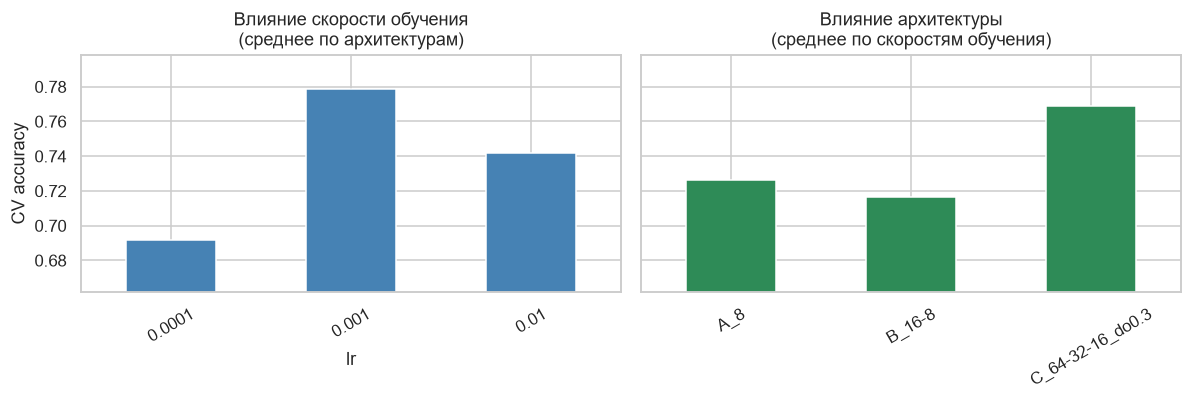

Размах по lr:           0.087
Размах по архитектуре: 0.052


In [21]:
lr_eff = summary.groupby("lr")["acc_mean"].mean()
arch_eff = summary.groupby("arch")["acc_mean"].mean()

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
lr_eff.plot.bar(ax=axes[0], color="steelblue")
axes[0].set(title="Влияние скорости обучения\n(среднее по архитектурам)", xlabel="lr", ylabel="CV accuracy")
arch_eff.plot.bar(ax=axes[1], color="seagreen")
axes[1].set(title="Влияние архитектуры\n(среднее по скоростям обучения)", xlabel="")
lo = min(lr_eff.min(), arch_eff.min()) - 0.03
axes[0].set_ylim(lo, max(lr_eff.max(), arch_eff.max()) + 0.02)
for ax in axes: ax.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

print(f"Размах по lr:           {lr_eff.max() - lr_eff.min():.3f}")
print(f"Размах по архитектуре: {arch_eff.max() - arch_eff.min():.3f}")

Оценил влияние каждого гиперпараметра отдельно: усреднил CV-accuracy по значениям другого гиперпараметра. Чем больше **размах** между столбцами, тем сильнее этот гиперпараметр влияет на качество. Размахи по `lr` и по архитектуре напечатаны под графиками: по `lr` он равен 0,087, по архитектуре 0,052, поэтому скорость обучения влияет на качество сильнее.

## 7. Лучшая конфигурация и финальная оценка

Лучшей считаю конфигурацию с максимальной средней валидационной accuracy по кросс-валидации. Затем переобучаю её на всей обучающей выборке (тем же протоколом: 100 эпох) пятью разными seed и оцениваю на отложенном тесте так же, как baseline.

In [22]:
best = summary.iloc[0]
BEST_CFG = {**ARCHS[best["arch"]], "lr": float(best["lr"])}
BEST_NAME = f"{best['arch']}__lr{best['lr']:g}"
print("Лучшая конфигурация:", BEST_NAME, BEST_CFG)

best_test = test_runs(BEST_CFG, BEST_NAME)
display(best_test.round(4))
print(f"Лучшая модель: test accuracy = {best_test.test_accuracy.mean():.3f} ± {best_test.test_accuracy.std():.3f} (5 seeds)")

Лучшая конфигурация: C_64-32-16_do0.3__lr0.0001 {'hidden': (64, 32, 16), 'dropout': 0.3, 'lr': 0.0001}


,seed,test_accuracy,test_loss,time_s
0,0,0.7273,0.4972,18.1411
1,1,0.7208,0.5182,15.4019
2,2,0.7273,0.5095,16.3880
3,3,0.7338,0.5059,16.4744
4,4,0.7078,0.5234,16.5692


Лучшая модель: test accuracy = 0.723 ± 0.010 (5 seeds)


Выбрал конфигурацию с наибольшей средней CV-accuracy, обучил её на всей обучающей выборке с пятью seed и оценил на тесте. Тест при этом не использовался ни для выбора конфигурации, ни во время обучения. Лучшей оказалась конфигурация C_64-32-16_do0.3 с `lr = 1e-4`; на тесте она показала 0,723 ± 0,010 (по пяти seed).

,CV accuracy,Test accuracy,± seeds
Dummy (самый частый класс),NaN,0.649,NaN
Логистическая регрессия,NaN,0.708,NaN
"Нейросеть baseline (B, lr=1e-3)",0.779,0.740,0.021
"Нейросеть, лучшая (C_64-32-16_do0.3__lr0.0001)",0.788,0.723,0.010


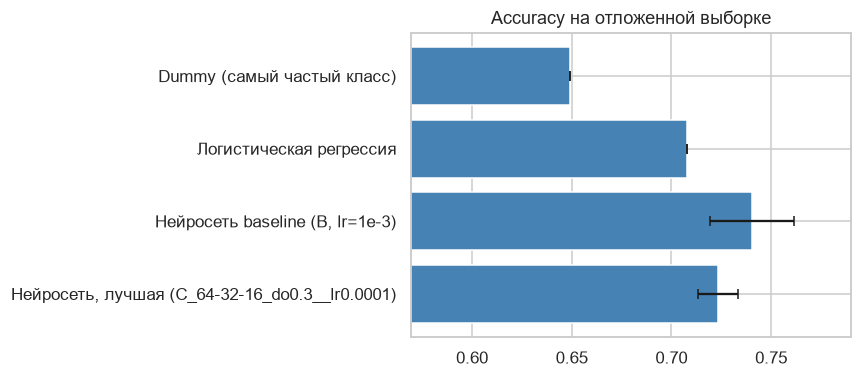

In [23]:
base_row = summary[(summary["arch"] == "B_16-8") & np.isclose(summary["lr"], 1e-3)].iloc[0]

final = pd.DataFrame({
    "Dummy (самый частый класс)": {"CV accuracy": np.nan, "Test accuracy": acc_dummy, "± seeds": np.nan},
    "Логистическая регрессия":    {"CV accuracy": np.nan, "Test accuracy": acc_logreg, "± seeds": np.nan},
    "Нейросеть baseline (B, lr=1e-3)": {"CV accuracy": base_row["acc_mean"], "Test accuracy": base_test.test_accuracy.mean(), "± seeds": base_test.test_accuracy.std()},
    f"Нейросеть, лучшая ({BEST_NAME})": {"CV accuracy": best["acc_mean"], "Test accuracy": best_test.test_accuracy.mean(), "± seeds": best_test.test_accuracy.std()},
}).T
display(final.round(3))

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(final.index[::-1], final["Test accuracy"][::-1], xerr=final["± seeds"].fillna(0)[::-1], color="steelblue", capsize=3)
ax.set_xlim(final["Test accuracy"].min() - 0.08, final["Test accuracy"].max() + 0.05)
ax.set_title("Accuracy на отложенной выборке")
plt.tight_layout()
plt.show()

Свёл в таблицу итоговое сравнение: dummy, логистическая регрессия, baseline-нейросеть и лучшая настроенная нейросеть. Для нейросетей приведены средняя CV-accuracy (на обучающей выборке), средняя точность на тесте и её разброс по пяти seed (столбец `± seeds`). Эти два столбца дополняют друг друга: CV устойчивее, так как опирается на всю обучающую выборку, а тест — независимая проверка на 154 объектах (стандартная ошибка accuracy около ±3 п.п.).

In [24]:
# Сравнение baseline и лучшей конфигурации на одних и тех же фолдах
base_folds = cv_df[cv_df["config"] == "B_16-8__lr0.001"].sort_values("fold")["val_accuracy"].values
best_folds = cv_df[cv_df["config"] == BEST_NAME].sort_values("fold")["val_accuracy"].values
diff = best_folds - base_folds
pd.DataFrame({"baseline": base_folds, "лучшая": best_folds, "разница": diff},
             index=pd.Index(range(1, 6), name="фолд")).round(4)

,baseline,лучшая,разница
фолд,,,
1,0.7886,0.8049,0.0163
2,0.7642,0.7724,0.0081
3,0.7886,0.8293,0.0407
4,0.7642,0.7724,0.0081
5,0.7869,0.7623,-0.0246


Сравнил baseline и лучшую конфигурацию по фолдам. Так как фолды одни и те же, видно, выигрывает ли лучшая конфигурация стабильно или только в среднем. Если разница в большинстве фолдов одного знака, улучшение устойчиво; если знаки перемешаны, улучшение в пределах шума. Если лучшая конфигурация совпала с baseline, разница везде нулевая.

## 8. Выводы

**1. Лучшая конфигурация.** По средней CV-accuracy первое место у архитектуры C (64-32-16 с dropout 0,3) при `lr = 1e-4`: accuracy 0,788 ± 0,028 (std по фолдам), loss 0,461. Но отрыв от соседей незначим: в пределах одного std (от 0,760) находятся ещё A при `lr = 1e-3` (0,785 ± 0,017), B при `lr = 1e-3` (0,779 ± 0,013), C при `lr = 1e-3` (0,772 ± 0,013) и A при `lr = 1e-2` (0,761 ± 0,022). Формально выбранная конфигурация к тому же самая нестабильная между фолдами (std 0,028), а её `val_loss` достигает минимума почти на последней, 100-й эпохе, то есть сеть ещё не сошлась. Конфигурация A при `lr = 1e-3` практически не уступает по accuracy (0,785), имеет меньший разброс (0,017) и самый низкий loss среди всех девяти (0,456), поэтому на практике её можно считать не хуже. Время обучения не различает конфигурации: на один фолд уходит 30–33 с во всех случаях.

**2. Сравнение с baseline.** Dummy-модель даёт 0,649, логистическая регрессия — 0,708 на тесте. Baseline-нейросеть (B, `lr = 1e-3`): CV accuracy 0,779, на тесте 0,740 ± 0,021. Лучшая настроенная (C, `lr = 1e-4`): CV accuracy 0,788, на тесте 0,723 ± 0,010. Прирост по CV составил +1,0 п.п., а на тесте результат на 1,7 п.п. ниже baseline. По фолдам лучшая конфигурация выигрывает в четырёх из пяти, но средняя разница (0,010) меньше её разброса между фолдами (0,023), а на тесте разница лежит в пределах разброса по seed и стандартной ошибки теста (около ±3 п.п.). Значит, **настройка в рамках этой сетки не дала надёжного улучшения**: baseline-конфигурация уже находится среди почти лучших. Обе нейросети немного превосходят логистическую регрессию на тесте (baseline на 3,2 п.п., лучшая настроенная на 1,5 п.п.), но и эта разница в пределах погрешности.

**3. Влияние гиперпараметров.** Сильнее влияет **скорость обучения**: размах средней CV-accuracy по `lr` равен 0,087, по архитектуре — 0,052. В среднем лучшая `lr` равна 1e-3 (0,779), затем 1e-2 (0,742), худшая 1e-4 (0,692). Среди архитектур лучшая C (0,769), затем A (0,726) и B (0,717). Гиперпараметры взаимодействуют: при `lr = 1e-4` архитектуры A и B практически не обучаются (0,634 и 0,653, что около доли самого частого класса), а C показывает лучший результат. Вероятная причина в том, что в C заметно больше параметров, и за 100 эпох при малой скорости она успевает обучиться, а маленькие сети нет.

**4. Переобучение и недообучение.** Явное **переобучение** (разрыв train−validation по accuracy больше 0,08 или рост val loss от минимума больше 0,10) у B при `lr = 1e-2` (accuracy на train 0,950, на validation 0,718; val loss в конце на 1,18 выше минимума, который достигается на 7-й эпохе) и у C при `lr = 1e-2` (разрыв 0,126, рост val loss 0,371, минимум на 8-й эпохе). У A при `lr = 1e-2` переобучение умеренное (разрыв 0,065, рост 0,072, минимум на 16-й эпохе). При `lr = 1e-3` оно слабое: разрыв 0,044–0,047 у B и C и 0,009 у A, рост val loss не больше 0,041. **Недообучение** у A и B при `lr = 1e-4`: accuracy на обучающих фолдах всего 0,646 и 0,671 (на уровне dummy-модели), а `val_loss` ещё снижается к 100-й эпохе. У C при `lr = 1e-4` разрыв отрицательный (−0,030: на train accuracy ниже, чем на validation, из-за dropout), `val_loss` не вырос, но минимум приходится на 99,6-ю эпоху, так что при большем числе эпох качество, вероятно, ещё выросло бы.

## 9. Заключение

В работе на датасете Pima Indians Diabetes освоен полный цикл обучения нейросети для классификации на TensorFlow. Данные проанализированы (умеренный дисбаланс классов 65/35, все признаки числовые, нули в пяти столбцах распознаны как скрытые пропуски). Построены baseline-модели (dummy, логистическая регрессия, нейросеть 16-8). Реализована 5-кратная стратифицированная кросс-валидация с предобработкой, обучаемой отдельно на каждом фолде. Методом Grid Search перебрано 9 конфигураций (3 скорости обучения × 3 архитектуры), для каждого фолда записаны логи TensorBoard с accuracy и loss. Конфигурации сравнены по точности, loss, времени обучения и устойчивости между фолдами, лучшая оценена на отложенной выборке и сопоставлена с baseline. Численные итоги и вывод об эффекте настройки приведены в разделе 8.